# CyberSentinel: Phishing Website Threat Classification

## Problem Statement
Cybersecurity systems need to identify suspicious websites before users interact with them. This project develops a Logistic Regression model to classify websites as **legitimate** or **potentially malicious** using URL and website-security characteristics.

**Option selected:** Option 5 — CyberSentinel: Phishing Website Threat Classification.

> This notebook covers the project workflow **up to and including statistical summary / dataset understanding and initial data-quality exploration**. The remaining modeling stages can be added after the dataset is loaded and inspected.


## Objective
- Understand the phishing-website dataset.
- Inspect its structure, feature types, and target variable.
- Check missing values, duplicates, data types, suspicious values, and class distribution.
- Produce descriptive/statistical summaries that will guide later preprocessing and Logistic Regression modeling.

The project brief requires these dataset-understanding and data-quality checks before model development. fileciteturn0file0L43-L67

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")


## 1. Load Dataset

Place the approved phishing website CSV file in the same folder as this notebook and update `FILE_NAME` if required. No absolute file path is used, in accordance with the project constraints. fileciteturn0file0L228-L245

In [3]:
# Change only the filename if your downloaded dataset has a different name
FILE_NAME = "dataset.csv"

file_path = Path(FILE_NAME)

if not file_path.exists():
    print(f"Dataset not found: {FILE_NAME}")
    print("Place the CSV file in the same folder as this notebook, then run this cell again.")
else:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully.")
    print(f"Shape: {df.shape}")


Dataset loaded successfully.
Shape: (11055, 32)


In [4]:
# If your dataset uses a different file name, you can also load it by selecting
# the first CSV file in the notebook directory.

if not file_path.exists():
    csv_files = list(Path(".").glob("*.csv"))
    if len(csv_files) == 1:
        df = pd.read_csv(csv_files[0])
        print(f"Automatically loaded: {csv_files[0].name}")
        print(f"Shape: {df.shape}")
    elif len(csv_files) > 1:
        print("Multiple CSV files found:")
        for f in csv_files:
            print(" -", f.name)
        print("Set FILE_NAME to the required phishing dataset.")


## 2. First Five Records

In [5]:
df.head()

,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,port,HTTPS_token,Request_URL,URL_of_Anchor,Links_in_tags,SFH,Submitting_to_email,Abnormal_URL,Redirect,on_mouseover,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,0,1,1,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,1,1,-1,1,0,-1,-1,1,1,0,1,1,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,1,1,-1,1,0,-1,-1,-1,-1,0,1,1,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,1,1,-1,-1,0,0,-1,1,1,0,1,1,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,1,1,1,1,0,0,-1,1,1,0,-1,1,-1,1,-1,-1,0,-1,1,1,1,1


## 3. Number of Rows and Columns

In [6]:
rows, columns = df.shape
print("Number of rows    :", rows)
print("Number of columns :", columns)

Number of rows    : 11055
Number of columns : 32


## 4. Column Names and Data Types

In [7]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
})

column_info

,Column,Data Type,Non-Null Count,Missing Count,Unique Values
index,index,int64,11055,0,11055
having_IPhaving_IP_Address,having_IPhaving_IP_Address,int64,11055,0,2
URLURL_Length,URLURL_Length,int64,11055,0,3
Shortining_Service,Shortining_Service,int64,11055,0,2
having_At_Symbol,having_At_Symbol,int64,11055,0,2
double_slash_redirecting,double_slash_redirecting,int64,11055,0,2
Prefix_Suffix,Prefix_Suffix,int64,11055,0,2
having_Sub_Domain,having_Sub_Domain,int64,11055,0,3
SSLfinal_State,SSLfinal_State,int64,11055,0,3
Domain_registeration_length,Domain_registeration_length,int64,11055,0,2


## 5. Identify Input Features and Target

The project brief defines the target for Option 5 as **legitimate website** versus **potentially malicious website**. The exact target-column name depends on the approved dataset selected. fileciteturn0file0L404-L429

The following code first displays all columns. Set `TARGET_COLUMN` to the actual target column in your dataset.

In [8]:
print("Available columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

# IMPORTANT: replace this with the actual target-column name.
TARGET_COLUMN = "Result"

if TARGET_COLUMN not in df.columns:
    print("\nTARGET_COLUMN is not present.")
    print("Set TARGET_COLUMN to the column representing legitimate/malicious websites.")
else:
    X = df.drop(columns=[TARGET_COLUMN])
    y = df[TARGET_COLUMN]
    print("\nInput features:", list(X.columns))
    print("Target variable:", TARGET_COLUMN)


Available columns:
1. index
2. having_IPhaving_IP_Address
3. URLURL_Length
4. Shortining_Service
5. having_At_Symbol
6. double_slash_redirecting
7. Prefix_Suffix
8. having_Sub_Domain
9. SSLfinal_State
10. Domain_registeration_length
11. Favicon
12. port
13. HTTPS_token
14. Request_URL
15. URL_of_Anchor
16. Links_in_tags
17. SFH
18. Submitting_to_email
19. Abnormal_URL
20. Redirect
21. on_mouseover
22. RightClick
23. popUpWidnow
24. Iframe
25. age_of_domain
26. DNSRecord
27. web_traffic
28. Page_Rank
29. Google_Index
30. Links_pointing_to_page
31. Statistical_report
32. Result

Input features: ['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 

## 6. Numerical and Categorical Features

In [9]:
if "X" in globals():
    numerical_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

    print("Numerical features:")
    print(numerical_features)

    print("\nCategorical / non-numerical features:")
    print(categorical_features)
else:
    print("Set TARGET_COLUMN correctly before running this cell.")

Numerical features:
['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']

Categorical / non-numerical features:
[]


## 7. Statistical Summary

For numerical variables, `describe()` gives count, mean, standard deviation, minimum, quartiles, and maximum. For categorical variables, it provides count, unique values, the most frequent value, and its frequency.

In [10]:
# Numerical statistical summary
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
index,11055.0,5528.000000,3191.447947,1.0,2764.5,5528.0,8291.5,11055.0
having_IPhaving_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URLURL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0


In [11]:
# Statistical summary including categorical columns
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
index,11055.0,5528.000000,3191.447947,1.0,2764.5,5528.0,8291.5,11055.0
having_IPhaving_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URLURL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0


## 8. Missing-Value Analysis

In [12]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

missing_summary

,Missing Count,Missing Percentage
index,0,0.0
having_IPhaving_IP_Address,0,0.0
Statistical_report,0,0.0
Links_pointing_to_page,0,0.0
Google_Index,0,0.0
Page_Rank,0,0.0
web_traffic,0,0.0
DNSRecord,0,0.0
age_of_domain,0,0.0
Iframe,0,0.0


## 9. Duplicate-Record Analysis

In [13]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(df)) * 100, 2), "%")

Number of duplicate rows: 0
Duplicate percentage: 0.0 %


## 10. Data-Type and Basic Quality Check

In [14]:
print("Data types:")
print(df.dtypes)

print("\nRows containing completely missing values:", df.isna().all(axis=1).sum())

# Count infinite values in numerical columns
numeric_df = df.select_dtypes(include=np.number)
if not numeric_df.empty:
    print("Infinite numeric values:", np.isinf(numeric_df.to_numpy()).sum())
else:
    print("No numerical columns detected.")

Data types:
index                          int64
having_IPhaving_IP_Address     int64
URLURL_Length                  int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic               

## 11. Target-Class Distribution

The project requires checking the distribution of both target classes and determining whether the dataset is balanced or imbalanced. fileciteturn0file0L59-L67

,Count,Percentage
Result,,
1,6157,55.69
-1,4898,44.31


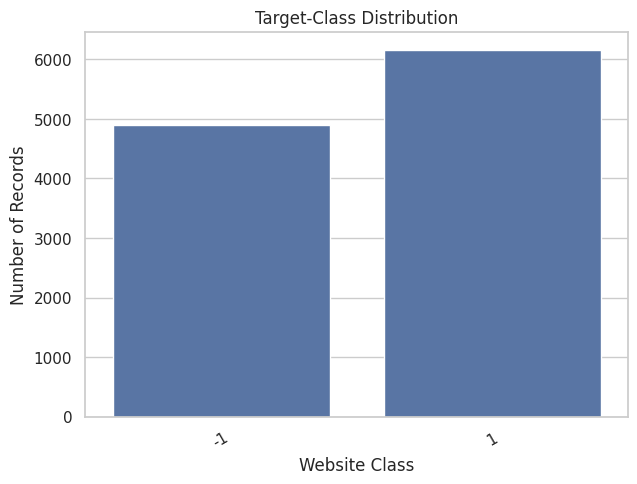

In [15]:
if TARGET_COLUMN in df.columns:
    target_counts = df[TARGET_COLUMN].value_counts(dropna=False)
    target_percent = (df[TARGET_COLUMN].value_counts(normalize=True, dropna=False) * 100).round(2)

    target_summary = pd.DataFrame({
        "Count": target_counts,
        "Percentage": target_percent
    })

    display(target_summary)

    plt.figure(figsize=(7, 5))
    sns.countplot(data=df, x=TARGET_COLUMN)
    plt.title("Target-Class Distribution")
    plt.xlabel("Website Class")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.show()
else:
    print("Set TARGET_COLUMN correctly before running this cell.")

## 12. Basic Suspicious-Value Checks

For a phishing-website dataset, suspicious values may include missing labels, infinite numerical values, or impossible values in numeric security/URL features. The exact domain rules depend on the selected dataset, so this section reports general checks without assuming unsupported feature ranges.

In [16]:
# Numeric range summary
if not numeric_df.empty:
    quality_summary = pd.DataFrame({
        "Minimum": numeric_df.min(),
        "Maximum": numeric_df.max(),
        "Mean": numeric_df.mean(),
        "Std Dev": numeric_df.std()
    })
    display(quality_summary)

# Show rows with infinite values, if any
if not numeric_df.empty:
    inf_mask = np.isinf(numeric_df).any(axis=1)
    print("Rows containing infinite numeric values:", inf_mask.sum())
else:
    print("No numerical columns available for range checks.")

,Minimum,Maximum,Mean,Std Dev
index,1,11055,5528.000000,3191.447947
having_IPhaving_IP_Address,-1,1,0.313795,0.949534
URLURL_Length,-1,1,-0.633198,0.766095
Shortining_Service,-1,1,0.738761,0.673998
having_At_Symbol,-1,1,0.700588,0.713598
double_slash_redirecting,-1,1,0.741474,0.671011
Prefix_Suffix,-1,1,-0.734962,0.678139
having_Sub_Domain,-1,1,0.063953,0.817518
SSLfinal_State,-1,1,0.250927,0.911892
Domain_registeration_length,-1,1,-0.336771,0.941629


Rows containing infinite numeric values: 0


## Initial Observations

After running the notebook with the approved dataset, record at least three observations here based on the actual outputs. Examples of observations to check are:

1. Whether the target classes are balanced or imbalanced.
2. Which features contain missing values or unusual numeric ranges.
3. Which numerical features show large differences in scale or spread.
4. Whether duplicate records are present.
5. Whether categorical features require encoding later.

**Do not write conclusions before running the cells; the project instructions require conclusions and findings to be based on actual outputs.** fileciteturn0file0L198-L208